# Alquiler — 05 Mejora del modelo final

**Modelo a mejorar:** el OLS Stepwise del notebook `04_Modelo_OLS.ipynb`, elegido allí por la regla de parsimonia del 1 % en test.

**Forma de mejora que se prueba en este notebook, definida antes de evaluar:**

El diagnóstico de `04` mostró error aproximadamente proporcional al nivel de precio, cola derecha pesada y compresión de los extremos. Se reutilizan las técnicas ya aplicadas en `04` y en la primera parte de este notebook —forward stepwise con BIC, OLS reajustado, términos polinómicos y validación temporal walk-forward— combinadas con modelar el alquiler en logaritmos:

1. **Referencia:** OLS en niveles con el subconjunto Stepwise de `04`, reproducido acá desde train.
2. **OLS en niveles con polinomio:** la referencia más `area_f_z` al cuadrado, `metro_f_z` al cuadrado y la interacción `area_f_z x metro_f_z`.
3. **OLS log:** OLS sobre `log(monthly_rent_rub)` con el subconjunto Stepwise en niveles. Para volver a rublos se aplica `exp(predicción) * factor de Duan`, donde el factor es el promedio de `exp(residuo en escala log)` calculado solo con los datos de ajuste de cada fold o del ajuste final. Sin ese factor, la retransformación subestimaría sistemáticamente el nivel.
4. **OLS log con polinomio:** el modelo log anterior más los mismos tres términos polinómicos.
5. **OLS log con Stepwise en log:** se repite el forward stepwise con BIC, pero ajustando sobre `log(monthly_rent_rub)`, y con ese subconjunto se ajusta el OLS log con corrección de Duan.
6. **OLS log con Stepwise en log y polinomio:** el candidato anterior más los tres términos polinómicos.

**Reglas de comparación, definidas antes de mirar test:**

- Todo subconjunto se selecciona solo con train: el Stepwise en niveles replica el de `04` y el Stepwise en log usa el mismo procedimiento y criterio BIC sobre la target transformada.
- El candidato campeón se elige por **MAE walk-forward dentro de train (2022, 2023 y 2024)**, porque el diagnóstico indica error proporcional y cola pesada: el MAE en rublos mide el error típico y es menos dominado por el segmento premium que la target winsorizada de train apenas contiene. El RMSE walk-forward se reporta como control y cualquier tradeoff queda explícito en tablas y gráficos.
- Todas las métricas se reportan en **rublos** sobre la target original: R2, RMSE y MAE, en validación temporal y en test.
- Test se usa solo para reportar al final. No elige candidato, subconjunto, términos ni correcciones. Como test ya se usó en `04` para elegir el modelo final, tampoco acá es una evaluación independiente; es una comparación exploratoria adicional.

## 1. Datos, split y reproducción del subconjunto Stepwise

Se conservan la target `monthly_rent_rub` en rublos, el split train 2021-2024 / test 2025-2026 y la matriz de 140 features de la etapa 03. El forward stepwise con BIC se replica sobre train con la misma aritmética de RSS de `04` para recuperar el subconjunto del modelo a mejorar, sin leer resultados de test.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

DATA_DIR = Path("..") / "data"
OUT_DIR = DATA_DIR / "processed"
TARGET = "monthly_rent_rub"

train = pd.read_csv(OUT_DIR / "rentals_train_fe.csv", parse_dates=["date_posted"])
test = pd.read_csv(OUT_DIR / "rentals_test_fe.csv", parse_dates=["date_posted"])
FEATURES_BASE = (["area_f_z", "metro_f_z", "furnished", "pets_allowed"]
                 + [c for c in train.columns if c.startswith("district_")]
                 + [c for c in train.columns if c.startswith("building_type_")]
                 + [c for c in train.columns if c.startswith("renovation_")])
assert len(FEATURES_BASE) == 140
assert all(c in test.columns for c in FEATURES_BASE)
assert train["date_posted"].max() < pd.Timestamp("2025-01-01") <= test["date_posted"].min()
print(f"train {len(train):,} (2021-2024) | test {len(test):,} (2025-2026) | p = {len(FEATURES_BASE)}")

def metricas(y_real, y_pred):
    y_real = np.asarray(y_real, float); y_pred = np.asarray(y_pred, float)
    return {"R2": float(r2_score(y_real, y_pred)),
            "RMSE_RUB": float(np.sqrt(mean_squared_error(y_real, y_pred))),
            "MAE_RUB": float(mean_absolute_error(y_real, y_pred))}

# Forward stepwise con BIC solo en train, replicando el procedimiento de 04.
Xg = np.column_stack([np.ones(len(train)), train[FEATURES_BASE].astype(float).to_numpy()])
yg = train[TARGET].astype(float).to_numpy()
XtX, Xty, yty = Xg.T @ Xg, Xg.T @ yg, float(yg @ yg)
pos = {c: i + 1 for i, c in enumerate(FEATURES_BASE)}
N_TR = len(train)

def rss_subconjunto(cols):
    idx = [0] + [pos[c] for c in cols]
    A = XtX[np.ix_(idx, idx)]; b = Xty[idx]
    try:
        beta = np.linalg.solve(A, b); rss = float(yty - b @ beta)
    except np.linalg.LinAlgError:
        beta = np.linalg.pinv(A) @ b; rss = float(yty - 2.0 * (b @ beta) + beta @ A @ beta)
    return max(rss, 0.0)

def bic_de(rss, k_cols):
    return N_TR * np.log(max(rss, 1e-9) / N_TR) + (k_cols + 1) * np.log(N_TR)

def forward_stepwise_bic(y_valores):
    # Mismo forward stepwise con BIC de 04, parametrizado por la target para reutilizarlo en niveles y en log.
    # Recomputa las cantidades Xty e yty para la target recibida; XtX no cambia porque depende solo de X.
    yv = np.asarray(y_valores, float)
    Xty_y = Xg.T @ yv
    yty_y = float(yv @ yv)
    def rss_y(cols):
        idx = [0] + [pos[c] for c in cols]
        A = XtX[np.ix_(idx, idx)]; b = Xty_y[idx]
        try:
            beta = np.linalg.solve(A, b); r = float(yty_y - b @ beta)
        except np.linalg.LinAlgError:
            beta = np.linalg.pinv(A) @ b; r = float(yty_y - 2.0 * (b @ beta) + beta @ A @ beta)
        return max(r, 0.0)
    sel_y, restantes_y = [], list(FEATURES_BASE)
    bic_y = bic_de(rss_y([]), 0)
    for _paso in range(140):
        mejor = None
        for c in restantes_y:
            bic_c = bic_de(rss_y(sel_y + [c]), len(sel_y) + 1)
            if mejor is None or bic_c < mejor[1]:
                mejor = (c, bic_c)
        if bic_y - mejor[1] < 2.0:
            break
        sel_y.append(mejor[0]); restantes_y.remove(mejor[0]); bic_y = mejor[1]
    return list(sel_y)

COLS_SWS = forward_stepwise_bic(train[TARGET].astype(float))
print(f"Subconjunto Stepwise reproducido solo con train: {len(COLS_SWS)} features")
print(", ".join(COLS_SWS))

train 14,820 (2021-2024) | test 4,841 (2025-2026) | p = 140


Subconjunto Stepwise reproducido solo con train: 109 features
metro_f_z, area_f_z, renovation_designer, district_Khamovniki, renovation_euro, district_Arbat, district_Tverskoy, district_Presnensky, district_Yakimanka, building_type_khrushchev, district_Zamoskvorechye, district_Dorogomilovo, district_Basmanny, district_Meshchansky, district_Krasnoselsky, district_Tagansky, district_Krylatskoye, district_Prospekt Vernadskogo, district_Lomonosovsky, district_Gagarinsky, district_Ramenki, building_type_stalin, building_type_monolith, building_type_brick, district_Filyovsky Park, district_Troparyovo-Nikulino, furnished, district_Kurkino, district_Akademichesky, district_Fili-Davydkovo, renovation_no_renovation, building_type_modern_panel, district_Khoroshyovsky, district_Cheryomushki, district_Shchapovskoye, district_Strogino, district_Shchukino, district_Sokol, district_Obruchevsky, district_Kuntsevo, district_Kotlovka, district_Begovoy, district_Mikhaylovo-Yartsevskoye, district_Krasnopak

## 2. Candidatos definidos antes de evaluar

Los candidatos difieren en tres decisiones declaradas a priori: la escala de la target (niveles o log), el origen del subconjunto (Stepwise en niveles o Stepwise repetido sobre la target en log) y la presencia de los términos polinómicos de las dos continuas. Ningún candidato usa test para construirse, y los subconjuntos completos quedan impresos en las celdas siguientes.

In [2]:
def diseno(df, cols, polinomio=False):
    X = df[list(cols)].astype(float).copy()
    if polinomio:
        X["area_f_z_sq"] = df["area_f_z"].astype(float) ** 2
        X["metro_f_z_sq"] = df["metro_f_z"].astype(float) ** 2
        X["area_x_metro"] = df["area_f_z"].astype(float) * df["metro_f_z"].astype(float)
    return X

def ajustar_predecir(tr, va, cols, log=False, polinomio=False):
    Xtr = sm.add_constant(diseno(tr, cols, polinomio), has_constant="add")
    Xva = sm.add_constant(diseno(va, cols, polinomio), has_constant="add")
    y = np.log(tr[TARGET].astype(float)) if log else tr[TARGET].astype(float)
    modelo = sm.OLS(y, Xtr).fit()
    pred = np.asarray(modelo.predict(Xva), float)
    if log:
        # Correccion de Duan: factor calculado solo con residuos del ajuste (tr), nunca con va.
        factor_duan = float(np.mean(np.exp(np.asarray(modelo.resid, float))))
        pred = np.exp(pred) * factor_duan
    return pred

COLS_SWS_LOG = forward_stepwise_bic(np.log(train[TARGET].astype(float)))
print(f"Subconjunto Stepwise sobre log de la target, solo con train: {len(COLS_SWS_LOG)} features")
print(", ".join(COLS_SWS_LOG))

CANDIDATOS = {
    "Referencia_niveles": {"cols": COLS_SWS, "log": False, "polinomio": False},
    "OLS_nivel_polinomio": {"cols": COLS_SWS, "log": False, "polinomio": True},
    "OLS_log": {"cols": COLS_SWS, "log": True, "polinomio": False},
    "OLS_log_polinomio": {"cols": COLS_SWS, "log": True, "polinomio": True},
    "OLS_log_Stepwise_log": {"cols": COLS_SWS_LOG, "log": True, "polinomio": False},
    "OLS_log_Stepwise_log_polinomio": {"cols": COLS_SWS_LOG, "log": True, "polinomio": True},
}
for nombre, cfg in CANDIDATOS.items():
    print(f"{nombre}: log={cfg['log']}, polinomio={cfg['polinomio']}, features base={len(cfg['cols'])}")

Subconjunto Stepwise sobre log de la target, solo con train: 140 features
metro_f_z, area_f_z, renovation_designer, renovation_euro, building_type_khrushchev, district_Khamovniki, district_Klyonovskoye, district_Shchapovskoye, district_Rogovskoye, district_Mikhaylovo-Yartsevskoye, district_Novofyodorovskoye, district_Krasnopakhorskoye, district_Kievsky, district_Pervomayskoye, district_Voronovskoye, district_Arbat, district_Tverskoy, district_Yakimanka, district_Presnensky, district_Dorogomilovo, district_Basmanny, district_Zamoskvorechye, district_Troitsk, building_type_monolith, building_type_stalin, district_Tagansky, district_Marushkinskoye, district_Krylatskoye, district_Meshchansky, district_Krasnoselsky, furnished, district_Ramenki, district_Lomonosovsky, district_Gagarinsky, district_Prospekt Vernadskogo, building_type_brick, district_Ryazanovskoye, district_Kokoshkino, district_Filimonkovskoye, renovation_no_renovation, district_Filyovsky Park, district_Troparyovo-Nikulino, di

## 3. Selección del campeón solo por validación temporal en train

Walk-forward 2022, 2023 y 2024: cada fold ajusta solo con el pasado, y en los modelos log el factor de Duan sale solo de ese pasado. El campeón es el de menor **MAE walk-forward medio**; el RMSE medio se muestra como control del tradeoff.

Validacion temporal dentro de train (promedio de folds 2022-2024, metricas en rublos)


,modelo,R2_WF,RMSE_WF,MAE_WF
2,OLS_log_Stepwise_log_polinomio,0.87,8858.44,6154.10
3,OLS_log_polinomio,0.87,8990.60,6224.77
4,OLS_nivel_polinomio,0.88,8392.81,6306.69
1,OLS_log_Stepwise_log,0.86,9218.97,6340.23
0,OLS_log,0.86,9366.98,6399.91
5,Referencia_niveles,0.87,8809.83,6696.87


,modelo,validacion,R2,RMSE_RUB,MAE_RUB
0,Referencia_niveles,2022,0.90,7661.58,5734.11
1,Referencia_niveles,2023,0.86,9189.68,7045.72
2,Referencia_niveles,2024,0.86,9578.22,7310.77
3,OLS_nivel_polinomio,2022,0.91,7108.13,5267.82
4,OLS_nivel_polinomio,2023,0.87,8819.86,6698.40
5,OLS_nivel_polinomio,2024,0.87,9250.43,6953.85
6,OLS_log,2022,0.88,8067.46,5087.27
7,OLS_log,2023,0.85,9619.51,6803.72
8,OLS_log,2024,0.84,10413.98,7308.75
9,OLS_log_polinomio,2022,0.89,7714.44,4893.57


Campeon por MAE walk-forward: OLS_log_Stepwise_log_polinomio (MAE WF = 6,154 RUB vs referencia 6,697 RUB; RMSE WF = 8,858 RUB vs referencia 8,810 RUB)


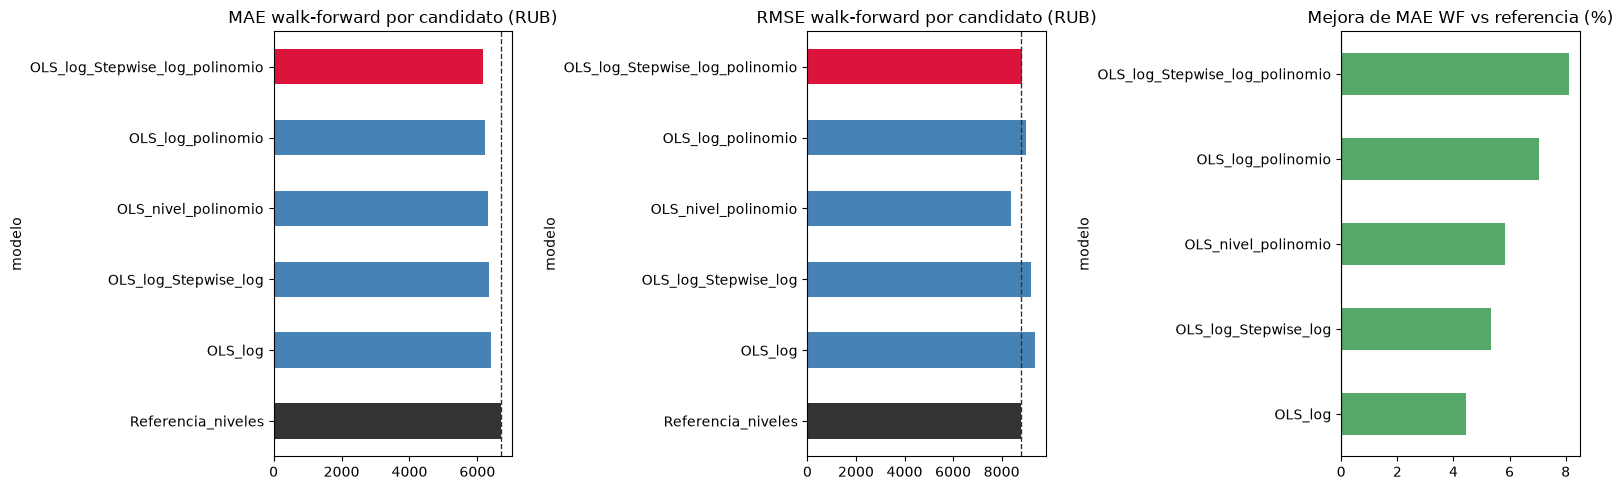

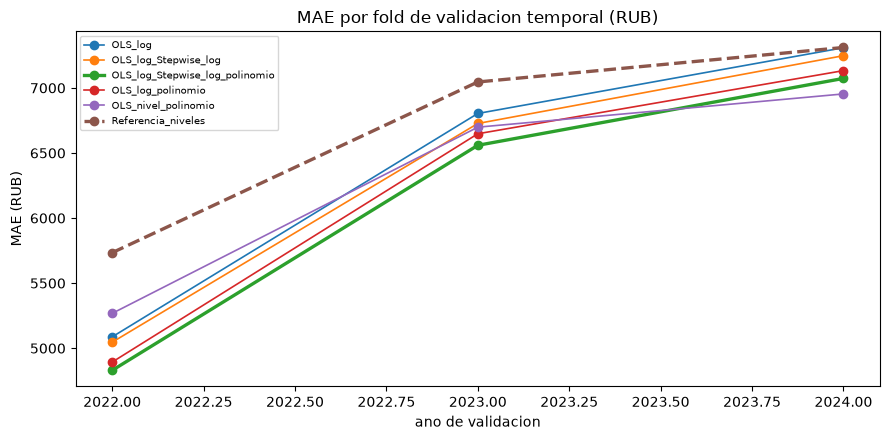

Resultado en train: OLS_log_Stepwise_log_polinomio mejora el MAE walk-forward de la referencia en 543 RUB (8.1%). El contraste de RMSE WF queda en la tabla como control.


In [3]:
filas_wf = []
for nombre, cfg in CANDIDATOS.items():
    for anio in (2022, 2023, 2024):
        tr = train[train["date_posted"].dt.year < anio]
        va = train[train["date_posted"].dt.year == anio]
        pred = ajustar_predecir(tr, va, cfg["cols"], log=cfg["log"], polinomio=cfg["polinomio"])
        filas_wf.append({"modelo": nombre, "validacion": anio, **metricas(va[TARGET], pred)})
tabla_wf = pd.DataFrame(filas_wf)
resumen_wf = (tabla_wf.groupby("modelo", as_index=False)
              .agg(R2_WF=("R2", "mean"), RMSE_WF=("RMSE_RUB", "mean"), MAE_WF=("MAE_RUB", "mean")))
resumen_wf = resumen_wf.sort_values("MAE_WF")
print("Validacion temporal dentro de train (promedio de folds 2022-2024, metricas en rublos)")
display(resumen_wf.round(2))
display(tabla_wf.round(2))
CAMPEON = str(resumen_wf.iloc[0]["modelo"])
_ref = resumen_wf.loc[resumen_wf["modelo"] == "Referencia_niveles"].iloc[0]
_cam = resumen_wf.iloc[0]
print(f"Campeon por MAE walk-forward: {CAMPEON} (MAE WF = {float(_cam['MAE_WF']):,.0f} RUB vs referencia {float(_ref['MAE_WF']):,.0f} RUB; "
      f"RMSE WF = {float(_cam['RMSE_WF']):,.0f} RUB vs referencia {float(_ref['RMSE_WF']):,.0f} RUB)")
# Graficos de la validacion temporal: donde esta la mejora y cuanto vale, fold por fold.
resumen_wf_plot = resumen_wf.set_index("modelo")
colores_wf = ["crimson" if m == CAMPEON else ("#333333" if m == "Referencia_niveles" else "steelblue") for m in resumen_wf_plot.index]
fig_wf, axes_wf = plt.subplots(1, 3, figsize=(16, 5))
resumen_wf_plot["MAE_WF"].plot.barh(ax=axes_wf[0], color=colores_wf)
axes_wf[0].axvline(float(_ref["MAE_WF"]), color="#333333", ls="--", lw=1)
axes_wf[0].set_title("MAE walk-forward por candidato (RUB)"); axes_wf[0].invert_yaxis()
resumen_wf_plot["RMSE_WF"].plot.barh(ax=axes_wf[1], color=colores_wf)
axes_wf[1].axvline(float(_ref["RMSE_WF"]), color="#333333", ls="--", lw=1)
axes_wf[1].set_title("RMSE walk-forward por candidato (RUB)"); axes_wf[1].invert_yaxis()
mejora_pct = (float(_ref["MAE_WF"]) - resumen_wf_plot["MAE_WF"]) / float(_ref["MAE_WF"]) * 100
mejora_pct.drop("Referencia_niveles").sort_values().plot.barh(ax=axes_wf[2], color="#55A868")
axes_wf[2].axvline(0, color="black", lw=0.8)
axes_wf[2].set_title("Mejora de MAE WF vs referencia (%)")
plt.tight_layout(); plt.show()

fig_folds, ax_folds = plt.subplots(figsize=(9, 4.5))
pivote_mae = tabla_wf.pivot(index="validacion", columns="modelo", values="MAE_RUB")
for modelo in pivote_mae.columns:
    lw = 2.4 if modelo in (CAMPEON, "Referencia_niveles") else 1.2
    ls = "-" if modelo != "Referencia_niveles" else "--"
    ax_folds.plot(pivote_mae.index, pivote_mae[modelo], marker="o", lw=lw, ls=ls, label=modelo)
ax_folds.set_title("MAE por fold de validacion temporal (RUB)")
ax_folds.set_xlabel("ano de validacion"); ax_folds.set_ylabel("MAE (RUB)"); ax_folds.legend(fontsize=7)
plt.tight_layout(); plt.show()

if CAMPEON == "Referencia_niveles":
    print("Resultado: ningun candidato log supero a la referencia en MAE walk-forward; no se declara mejora.")
else:
    print(f"Resultado en train: {CAMPEON} mejora el MAE walk-forward de la referencia en {float(_ref['MAE_WF'] - _cam['MAE_WF']):,.0f} RUB "
          f"({float(100 * (_ref['MAE_WF'] - _cam['MAE_WF']) / _ref['MAE_WF']):.1f}%). El contraste de RMSE WF queda en la tabla como control.")

## 4. Reporte en test (no usado para elegir)

Con el campeón ya cerrado por validación temporal, se ajusta cada candidato en todo train y se reporta test una sola vez. Estas cifras no eligieron nada y, como test ya participó en la elección del modelo final de `04`, deben leerse como comparación exploratoria, no como evaluación independiente.

Ajuste en todo train y reporte en test (test no eligio candidato)


,modelo,R2_train,RMSE_RUB_train,MAE_RUB_train,R2_test,RMSE_RUB_test,MAE_RUB_test,R2_WF,RMSE_WF,MAE_WF
0,Referencia_niveles,0.90,7933.87,6170.92,0.81,13653.18,7802.50,0.87,8809.83,6696.87
1,OLS_nivel_polinomio,0.91,7483.78,5695.52,0.83,12926.65,7294.84,0.88,8392.81,6306.69
2,OLS_log,0.88,8523.36,5575.35,0.88,10599.08,6491.83,0.86,9366.98,6399.91
3,OLS_log_polinomio,0.89,8052.06,5352.70,0.89,10560.75,6384.14,0.87,8990.60,6224.77
4,OLS_log_Stepwise_log,0.89,8339.15,5441.85,0.89,10562.90,6426.28,0.86,9218.97,6340.23
5,OLS_log_Stepwise_log_polinomio,0.90,7889.56,5198.72,0.89,10387.81,6278.05,0.87,8858.44,6154.10


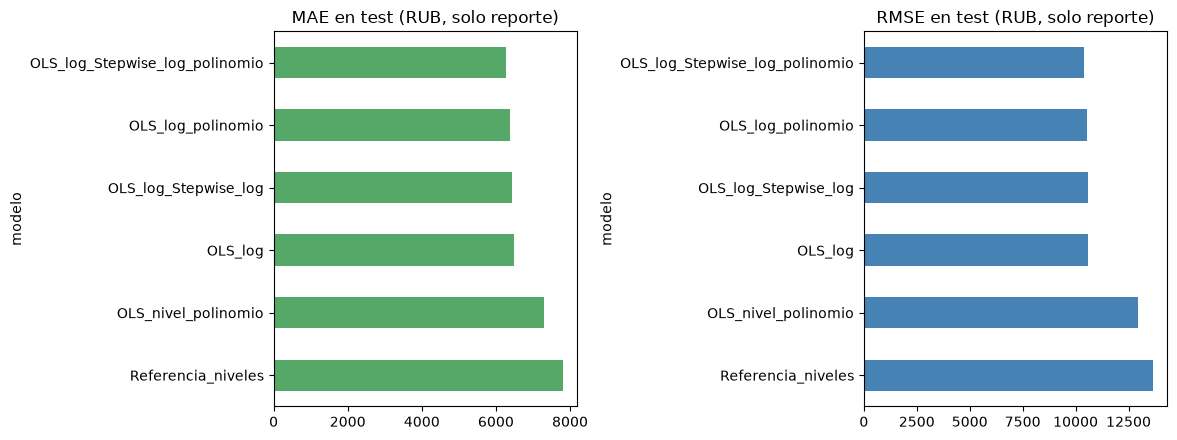

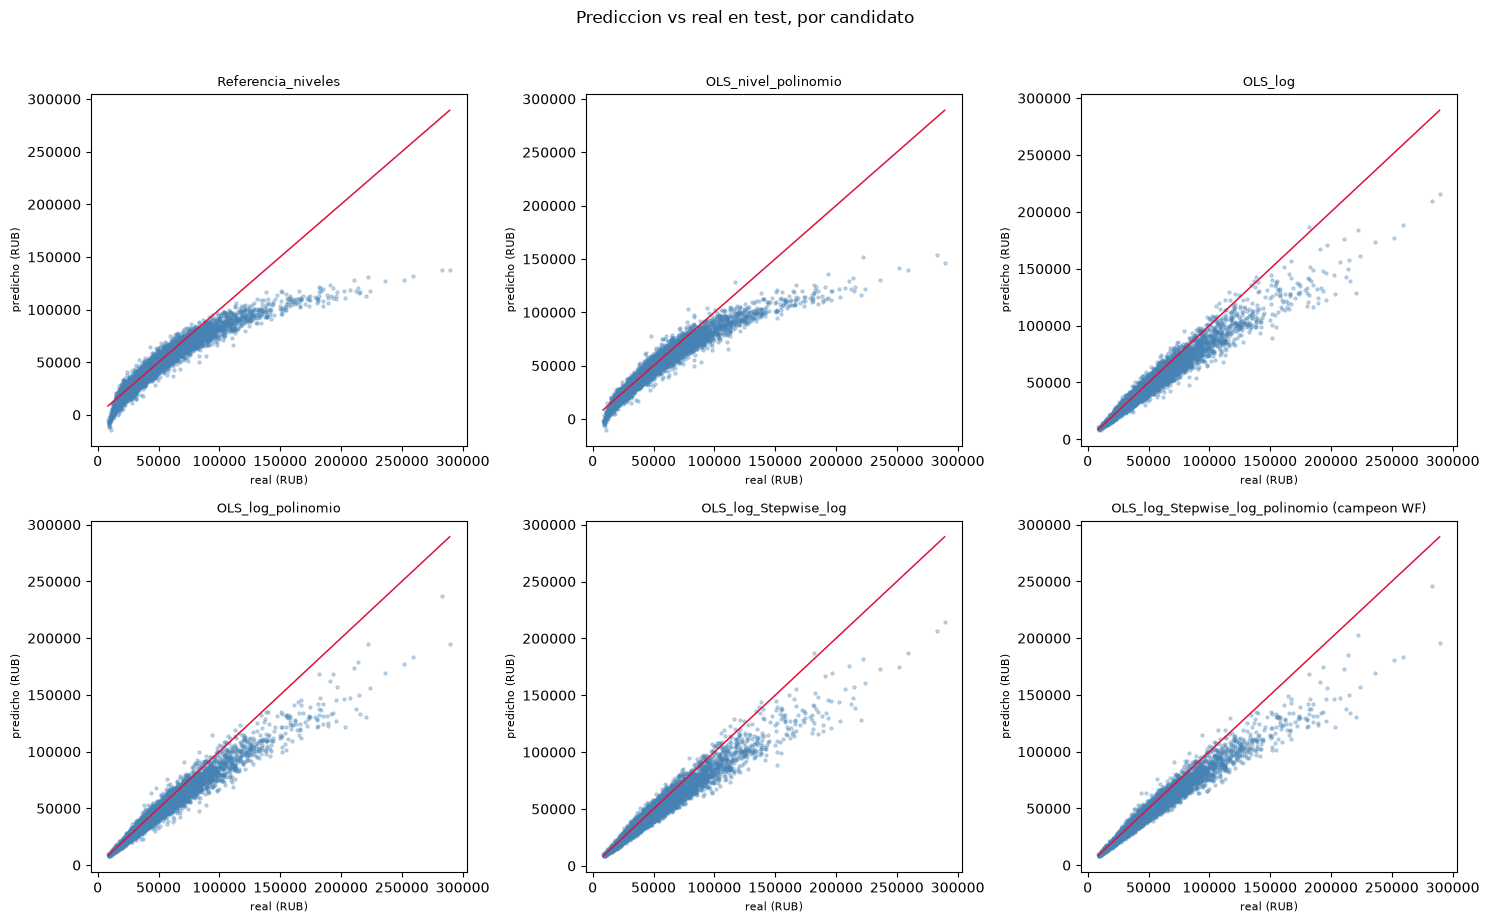

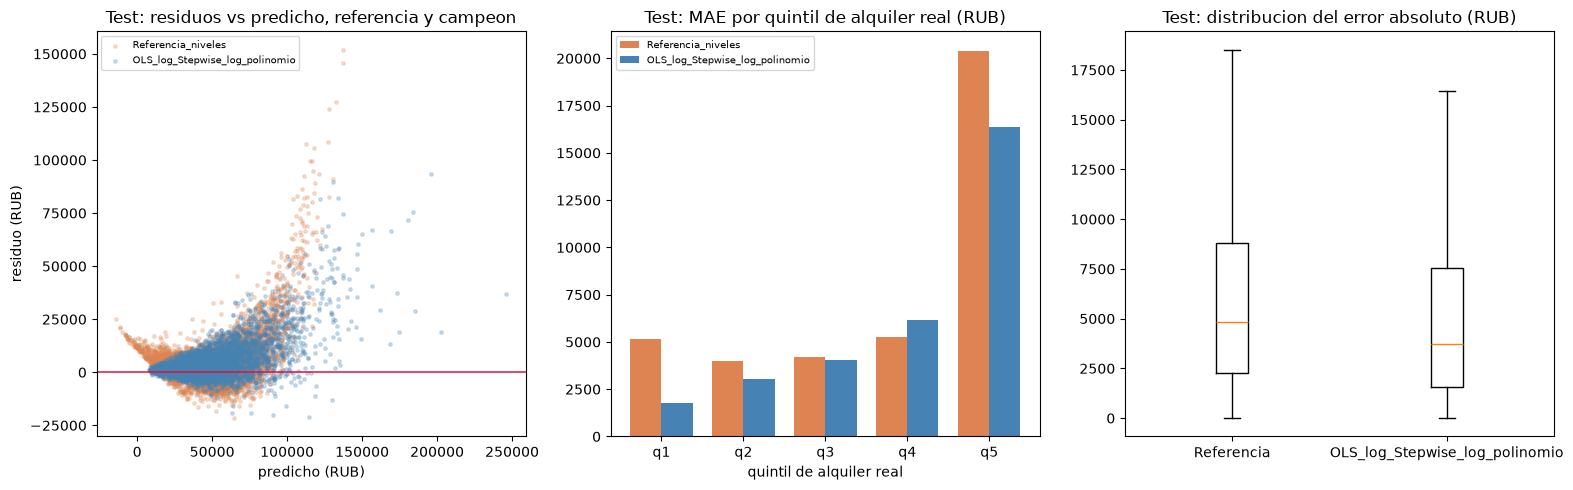

MAE en test por quintil de alquiler real, referencia contra campeon:


,Referencia_niveles,OLS_log_Stepwise_log_polinomio
q1,5156.0,1763.0
q2,3993.0,3031.0
q3,4185.0,4043.0
q4,5276.0,6183.0
q5,20407.0,16389.0


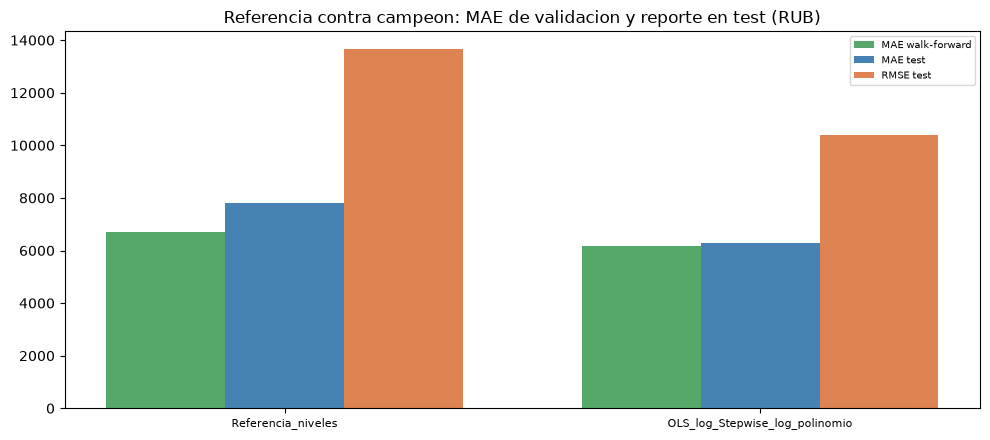

Lectura dinamica: el campeon por validacion temporal fue OLS_log_Stepwise_log_polinomio. En el reporte de test, su MAE fue 6,278 RUB frente a 7,803 RUB de la referencia, y su RMSE 10,388 RUB frente a 13,653 RUB. Estas diferencias de test son descriptivas: no participaron en la eleccion del campeon.


In [4]:
filas_test = []
preds_test = {}
for nombre, cfg in CANDIDATOS.items():
    pred_tr = ajustar_predecir(train, train, cfg["cols"], log=cfg["log"], polinomio=cfg["polinomio"])
    pred_te = ajustar_predecir(train, test, cfg["cols"], log=cfg["log"], polinomio=cfg["polinomio"])
    preds_test[nombre] = pred_te
    filas_test.append({"modelo": nombre,
                       **{f"{k}_train": v for k, v in metricas(train[TARGET], pred_tr).items()},
                       **{f"{k}_test": v for k, v in metricas(test[TARGET], pred_te).items()}})
tabla_test = pd.DataFrame(filas_test)
# Agregar la validacion temporal ya calculada para una lectura en un solo lugar.
tabla_test = tabla_test.merge(resumen_wf, on="modelo", how="left")
print("Ajuste en todo train y reporte en test (test no eligio candidato)")
display(tabla_test.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
orden = tabla_test.sort_values("MAE_RUB_test")
orden.set_index("modelo")["MAE_RUB_test"].plot.barh(ax=axes[0], color="#55A868")
axes[0].set_title("MAE en test (RUB, solo reporte)"); axes[0].invert_yaxis()
orden.set_index("modelo")["RMSE_RUB_test"].plot.barh(ax=axes[1], color="steelblue")
axes[1].set_title("RMSE en test (RUB, solo reporte)"); axes[1].invert_yaxis()
plt.tight_layout(); plt.show()

fig2, axes2 = plt.subplots(2, 3, figsize=(15, 9), squeeze=False)
for ax, nombre in zip(axes2.ravel(), CANDIDATOS):
    ax.scatter(test[TARGET], preds_test[nombre], s=5, alpha=0.3, color="steelblue")
    lim = [float(test[TARGET].min()), float(test[TARGET].max())]
    ax.plot(lim, lim, color="crimson", lw=1.1)
    marca = " (campeon WF)" if nombre == CAMPEON else ""
    ax.set_title(f"{nombre}{marca}", fontsize=9)
    ax.set_xlabel("real (RUB)", fontsize=8); ax.set_ylabel("predicho (RUB)", fontsize=8)
fig2.suptitle("Prediccion vs real en test, por candidato", y=1.02)
plt.tight_layout(); plt.show()

# Graficos para ver como mejora: residuos, error por tramo de precio y distribucion del error absoluto en test.
fig_mejora, axes_mejora = plt.subplots(1, 3, figsize=(16, 5))
for nombre_g, color_g in [("Referencia_niveles", "#DD8452"), (CAMPEON, "steelblue")]:
    pred_g = np.asarray(preds_test[nombre_g], float)
    resid_g = np.asarray(test[TARGET], float) - pred_g
    axes_mejora[0].scatter(pred_g, resid_g, s=6, alpha=0.25, color=color_g, label=nombre_g)
axes_mejora[0].axhline(0, color="crimson", lw=1.1)
axes_mejora[0].set_title("Test: residuos vs predicho, referencia y campeon")
axes_mejora[0].set_xlabel("predicho (RUB)"); axes_mejora[0].set_ylabel("residuo (RUB)"); axes_mejora[0].legend(fontsize=7)

tramos_precio = pd.qcut(test[TARGET].astype(float), 5, labels=["q1", "q2", "q3", "q4", "q5"])
mae_tramos = {}
for nombre_g in ["Referencia_niveles", CAMPEON]:
    err_abs = np.abs(np.asarray(test[TARGET], float) - np.asarray(preds_test[nombre_g], float))
    mae_tramos[nombre_g] = pd.Series(err_abs).groupby(np.asarray(tramos_precio)).mean()
tabla_mae_tramos = pd.DataFrame(mae_tramos)
x_pos = np.arange(len(tabla_mae_tramos)); ancho = 0.38
axes_mejora[1].bar(x_pos - ancho / 2, tabla_mae_tramos["Referencia_niveles"], width=ancho, label="Referencia_niveles", color="#DD8452")
axes_mejora[1].bar(x_pos + ancho / 2, tabla_mae_tramos[CAMPEON], width=ancho, label=CAMPEON, color="steelblue")
axes_mejora[1].set_xticks(x_pos); axes_mejora[1].set_xticklabels(tabla_mae_tramos.index)
axes_mejora[1].set_title("Test: MAE por quintil de alquiler real (RUB)")
axes_mejora[1].set_xlabel("quintil de alquiler real"); axes_mejora[1].legend(fontsize=7)

errores_abs = [np.abs(np.asarray(test[TARGET], float) - np.asarray(preds_test[n], float)) for n in ["Referencia_niveles", CAMPEON]]
axes_mejora[2].boxplot(errores_abs, tick_labels=["Referencia", CAMPEON], showfliers=False)
axes_mejora[2].set_title("Test: distribucion del error absoluto (RUB)")
plt.tight_layout(); plt.show()
print("MAE en test por quintil de alquiler real, referencia contra campeon:")
display(tabla_mae_tramos.round(0))

fig_comp_wf_test, ax_cwt = plt.subplots(figsize=(10, 4.5))
comp_cwt = tabla_test.set_index("modelo").loc[["Referencia_niveles", CAMPEON]]
x_pos2 = np.arange(len(comp_cwt)); ancho2 = 0.25
ax_cwt.bar(x_pos2 - ancho2, comp_cwt["MAE_WF"], width=ancho2, label="MAE walk-forward", color="#55A868")
ax_cwt.bar(x_pos2, comp_cwt["MAE_RUB_test"], width=ancho2, label="MAE test", color="steelblue")
ax_cwt.bar(x_pos2 + ancho2, comp_cwt["RMSE_RUB_test"], width=ancho2, label="RMSE test", color="#DD8452")
ax_cwt.set_xticks(x_pos2); ax_cwt.set_xticklabels(comp_cwt.index, fontsize=8)
ax_cwt.set_title("Referencia contra campeon: MAE de validacion y reporte en test (RUB)")
ax_cwt.legend(fontsize=7)
plt.tight_layout(); plt.show()

_fila_campeon_test = tabla_test.loc[tabla_test["modelo"] == CAMPEON].iloc[0]
_fila_ref_test = tabla_test.loc[tabla_test["modelo"] == "Referencia_niveles"].iloc[0]
print(f"Lectura dinamica: el campeon por validacion temporal fue {CAMPEON}. En el reporte de test, su MAE fue "
      f"{float(_fila_campeon_test['MAE_RUB_test']):,.0f} RUB frente a {float(_fila_ref_test['MAE_RUB_test']):,.0f} RUB de la referencia, "
      f"y su RMSE {float(_fila_campeon_test['RMSE_RUB_test']):,.0f} RUB frente a {float(_fila_ref_test['RMSE_RUB_test']):,.0f} RUB. "
      "Estas diferencias de test son descriptivas: no participaron en la eleccion del campeon.")

## 5. Cierre

Este notebook extendió la mejora del modelo final de `04` reutilizando las técnicas ya aplicadas en el proyecto: forward stepwise con BIC para seleccionar subconjuntos, OLS reajustado sobre cada subconjunto, términos polinómicos de las continuas y validación temporal walk-forward para elegir sin tocar test. La escala logarítmica con corrección de Duan es la forma funcional que ataca el error proporcional al precio diagnosticado en `04`.

La conclusión válida es la de la validación temporal de la sección 3 y sus gráficos: el campeón es el candidato con menor MAE walk-forward, y la mejora frente a la referencia se mide ahí, fold por fold. Lo que se ve en test en la sección 4 —predicho contra real, residuos, error por tramo de precio y distribución del error absoluto— es un reporte posterior sobre un test ya reutilizado en `04`, no una confirmación independiente.

Si en otra ejecución el campeón fuera la referencia, la conclusión sería que ninguna de estas combinaciones mejora el modelo en el criterio predefinido. Una tendencia temporal explícita queda como paso siguiente posible y no forma parte de los candidatos evaluados en este notebook.